# Day 9 : Missing Values ​​& Outliers Flotation Sensor

Sensor proses di pabrik flotasi kadang menghasilkan **nilai janggal** — lonjakan ekstrem akibat gangguan alat, atau data hilang saat sensor mati.

Sebelum data dipakai untuk model, Saya akan **mendeteksi outlier & missing value** dan memutuskan cara menanganinya.

🎯 **Tujuan Pembelajaran**
> - Memeriksa **missing value** pada data sensor.
> - Mendeteksi **outlier** dengan aturan **IQR** memakai `tandai_outlier_iqr`.
> - Memahami dampak outlier terhadap statistik (rata-rata vs median).
> - Membandingkan strategi: **membiarkan** vs **clip/winsorize**.

## About the Dataset

Saya akan kembali memakai **Quality Prediction in a Mining Process** (flotasi bijih besi), fokus pada beberapa **sensor proses** yang rawan outlier.

- **Sumber:** [Kaggle — edumagalhaes/quality-prediction-in-a-mining-process](https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process)
- **Ukuran asli:** 737.453 baris × 24 kolom (angka pakai **koma desimal** → `decimal=","`).

Saya akan **ambil sampel 30.000 baris** (`random_state=42`) agar ringan.

| Sensor | Arti |
|--------|------|
| `Ore Pulp pH` | Keasaman bubur bijih |
| `Ore Pulp Density` | Kepadatan bubur bijih |
| `Starch Flow` | Aliran reagen pati |
| `Amina Flow` | Aliran reagen amina |
| `Flotation Column 01 Air Flow` | Aliran udara kolom flotasi 1 |
| `% Silica Concentrate` | Kadar silika hasil (target mutu) |

## Import Library

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Import Dataset

In [15]:
!pip install kaggle
!mkdir ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json
!kaggle datasets download -d edumagalhaes/quality-prediction-in-a-mining-process
!unzip quality-prediction-in-a-mining-process.zip

mkdir: cannot create directory ‘/root/.kaggle’: File exists
cp: cannot stat 'kaggle.json': No such file or directory
chmod: cannot access '/root/.kaggle/kaggle.json': No such file or directory
Dataset URL: https://www.kaggle.com/datasets/edumagalhaes/quality-prediction-in-a-mining-process
License(s): CC0-1.0
quality-prediction-in-a-mining-process.zip: Skipping, found more recently modified local copy (use --force to force download)
Archive:  quality-prediction-in-a-mining-process.zip
replace MiningProcess_Flotation_Plant_Database.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: MiningProcess_Flotation_Plant_Database.csv  


In [16]:
df = pd.read_csv('/content/MiningProcess_Flotation_Plant_Database.csv', decimal=",")
df.head()

,date,% Iron Feed,% Silica Feed,Starch Flow,Amina Flow,Ore Pulp Flow,Ore Pulp pH,Ore Pulp Density,Flotation Column 01 Air Flow,Flotation Column 02 Air Flow,...,Flotation Column 07 Air Flow,Flotation Column 01 Level,Flotation Column 02 Level,Flotation Column 03 Level,Flotation Column 04 Level,Flotation Column 05 Level,Flotation Column 06 Level,Flotation Column 07 Level,% Iron Concentrate,% Silica Concentrate
0,2017-03-10 01:00:00,55.2,16.98,3019.53,557.434,395.713,10.0664,1.74,249.214,253.235,...,250.884,457.396,432.962,424.954,443.558,502.255,446.370,523.344,66.91,1.31
1,2017-03-10 01:00:00,55.2,16.98,3024.41,563.965,397.383,10.0672,1.74,249.719,250.532,...,248.994,451.891,429.560,432.939,448.086,496.363,445.922,498.075,66.91,1.31
2,2017-03-10 01:00:00,55.2,16.98,3043.46,568.054,399.668,10.0680,1.74,249.741,247.874,...,248.071,451.240,468.927,434.610,449.688,484.411,447.826,458.567,66.91,1.31
3,2017-03-10 01:00:00,55.2,16.98,3047.36,568.665,397.939,10.0689,1.74,249.917,254.487,...,251.147,452.441,458.165,442.865,446.210,471.411,437.690,427.669,66.91,1.31
4,2017-03-10 01:00:00,55.2,16.98,3033.69,558.167,400.254,10.0697,1.74,250.203,252.136,...,248.928,452.441,452.900,450.523,453.670,462.598,443.682,425.679,66.91,1.31


In [17]:
df.shape

(737453, 24)

In [18]:
# Ambil 30.000 sample saja
df_sample = df.sample(n=30000, random_state=42)
df_sample.shape

(30000, 24)

In [19]:
sensor = ["Ore Pulp pH", "Ore Pulp Density", "Starch Flow", "Amina Flow",
          "Flotation Column 01 Air Flow", "% Silica Concentrate"]

## Check for Missing Values

Langkah pertama: pastikan tidak ada data hilang tersembunyi.

In [20]:
df_sample[sensor].isnull().sum()

,0
Ore Pulp pH,0
Ore Pulp Density,0
Starch Flow,0
Amina Flow,0
Flotation Column 01 Air Flow,0
% Silica Concentrate,0


**Interpretation:**


- Kelengkapan data (0 missing values):
  - Setiap variabel—mulai dari parameter proses flotasi (Ore Pulp pH, Ore Pulp Density, Starch Flow, Amina Flow, Flotation Column 01 Air Flow) hingga kadar silika keluaran (% Silica Concentrate)—memiliki entri terisi penuh pada sampel data tersebut.

- Kesiapan analisis awal:
  - tidak perlu melakukan imputation (pengisian nilai kosong) atau drop rows akibat NaN pada kolom-kolom ini di df_sample.

## Outlier Detection Using the IQR Rule

Aturan IQR menandai nilai di luar `[Q1 - 1.5·IQR, Q3 + 1.5·IQR]` sebagai outlier.

Saya akan menghitung berapa banyak outlier tiap sensor memakai helper `tandai_outlier_iqr`.

In [21]:
def tandai_outlier_iqr(
    data: pd.DataFrame, kolom: str, k: float = 1.5
) -> pd.Series:
    """Kembalikan mask boolean baris yang outlier pada `kolom` dengan aturan IQR.

    Outlier = nilai di luar [Q1 - k*IQR, Q3 + k*IQR]. Pakai untuk memeriksa atau
    membuang pencilan, mis. `df[~tandai_outlier_iqr(df, "harga")]`.
    """
    # Konversi kolom ke numeric jika masih berupa string
    seri = data[kolom]
    if seri.dtype == object:
        seri = pd.to_numeric(seri.astype(str).str.replace(",", "."), errors="coerce")

    q1 = seri.quantile(0.25)
    q3 = seri.quantile(0.75)
    iqr = q3 - q1
    batas_bawah = q1 - k * iqr
    batas_atas = q3 + k * iqr
    return (seri < batas_bawah) | (seri > batas_atas)


def ringkas_outlier_iqr(
    data: pd.DataFrame, kolom_list: list[str], k: float = 1.5
) -> pd.DataFrame:
    """Buat tabel ringkasan jumlah dan persentase outlier IQR per kolom."""
    # Buat copy lokal agar tidak memicu SettingWithCopyWarning
    data_copy = data.copy()
    for kol in kolom_list:
        if data_copy[kol].dtype == object:
            data_copy[kol] = pd.to_numeric(data_copy[kol].astype(str).str.replace(",", "."), errors="coerce")

    ringkas = pd.DataFrame(
        {
            kol: {
                "jumlah_outlier": int((mask := tandai_outlier_iqr(data_copy, kol, k=k)).sum()),
                "persen": round(float(mask.mean()) * 100, 2),
            }
            for kol in kolom_list
        }
    ).T
    ringkas["jumlah_outlier"] = ringkas["jumlah_outlier"].astype(int)
    return ringkas

# Menjalankan ringkasan outlier pada df_sample yang sudah dibersihkan
ringkas = ringkas_outlier_iqr(df_sample, sensor, k=1.5)
ringkas

,jumlah_outlier,persen
Ore Pulp pH,402,1.34
Ore Pulp Density,1892,6.31
Starch Flow,40,0.13
Amina Flow,429,1.43
Flotation Column 01 Air Flow,1,0.00
% Silica Concentrate,226,0.75


**Interpretation:**

- Sebagian besar data masih tergolong normal:
  - Persentase outlier di hampir semua kolom berada di bawah 1,5%, kecuali Ore Pulp Density (6,31% / 1.892 baris) yang paling sering keluar dari rentang normal.

- Paling sedikit penyimpangannya:
  - Flotation Column 01 Air Flow hanya memiliki 1 baris outlier (0,00%), diikuti Starch Flow (0,13% / 40 baris).

- Variabel target (% Silica Concentrate):
  - Ada 226 baris (0,75%) yang menyimpang dari pola umum kadar silika.

- Parameter aliran & pH:
  - Amina Flow (1,43%) dan Ore Pulp pH (1,34%) memiliki porsi penyimpangan yang mirip dan tergolong kecil.

## The Impact of Outliers on Statistics

Outlier menarik **rata-rata**, tetapi **median** lebih tahan. Kita bandingkan pada satu sensor.

In [22]:
kol = "Amina Flow"

# Pastikan kolom di df_sample dikonversi ke numerik terlebih dahulu
df_sample[kol] = pd.to_numeric(df_sample[kol].astype(str).str.replace(",", "."), errors="coerce")

seri = df_sample[kol]
mask = tandai_outlier_iqr(df_sample, kol)

rata_rata = seri.mean()
median = seri.median()
rata_rata_bersih = seri.loc[~mask].mean()

print(f"[{kol}]")
print(f"  rata-rata               : {rata_rata:.2f}")
print(f"  median                  : {median:.2f}")
print(f"  rata-rata tanpa outlier : {rata_rata_bersih:.2f}")

[Amina Flow]
  rata-rata               : 489.04
  median                  : 504.88
  rata-rata tanpa outlier : 491.95


**Interpretation:**


Hasil tersebut menunjukkan distribusi nilai **Amina Flow** cenderung sedikit miring ke kiri (*left-skewed*), dengan beberapa nilai rendah yang menarik rata-rata turun.

### Poin Utama

* **Nilai tengah lebih tinggi dari rata-rata:**
  -  *Median* (`504,88`) lebih besar daripada *rata-rata* (`489,04`). Artinya, separuh data berada di atas `504,88`, dan ada nilai-nilai rendah yang menarik rata-rata ke bawah.

* **Dampak *outlier* relatif kecil:**
  - Saat *outlier* dibuang, *rata-rata tanpa outlier* hanya naik sekitar `2,91` poin (dari `489,04` menjadi `491,95`). Meski jumlah *outlier*-nya ada `429` baris (`1,43%`), pengaruhnya ke rata-rata tidak terlalu besar.
    
* **Mana yang lebih pas dipakai?**
  - Gunakan **median (`504,88`)** jika ingin melihat nilai tipikal harian/umum tanpa terpengaruh nilai ekstrem rendah, dan gunakan **rata-rata** jika perhitungan berikutnya membutuhkan nilai total/agregat.

## Exploratory Data Analysis & Visualization

### a) Boxplot for several sensors (outliers appear as dots)

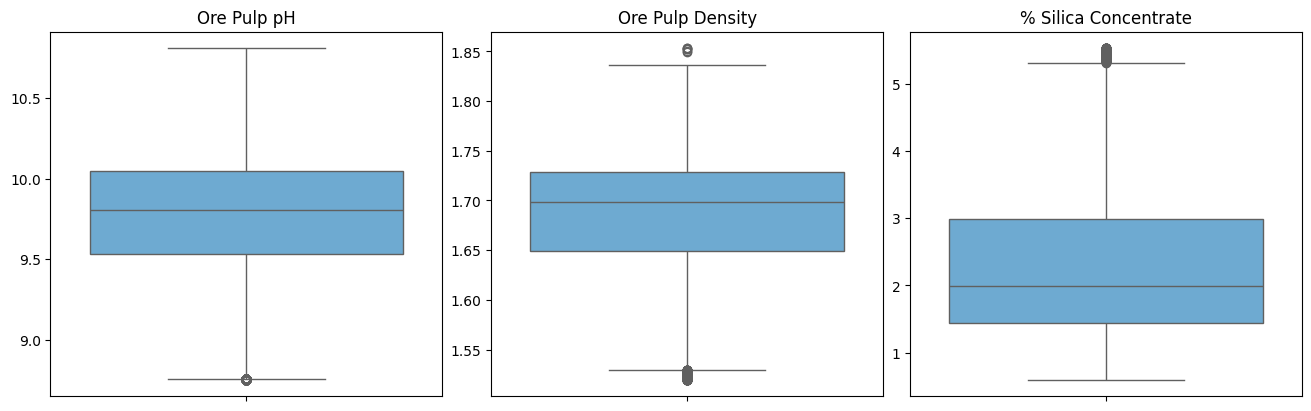

In [23]:
sensor_num = ["Ore Pulp pH", "Ore Pulp Density", "% Silica Concentrate"]

# Memastikan semua kolom target telah dikonversi ke tipe data float (numerik)
for kol in sensor_num:
    if df_sample[kol].dtype == object:
        df_sample[kol] = pd.to_numeric(df_sample[kol].astype(str).str.replace(",", "."), errors="coerce")

fig, axes = plt.subplots(1, len(sensor_num), figsize=(13, 4), constrained_layout=True)

for ax, kol in zip(axes, sensor_num):
    sns.boxplot(data=df_sample, y=kol, ax=ax, color="#5DADE2")
    ax.set_title(kol)
    ax.set_ylabel("")

plt.show()

**Interpretation:**

Ringkasnya, grafik ini memperlihatkan sebaran dan nilai ekstrem pada tiga kolom di `df_sample`:

* **Ore Pulp pH:**
  - Kebanyakan nilai berkumpul di sekitar **9,8** (kisaran tengah **9,5–10,1**), dengan sedikit nilai rendah hingga sekitar **8,75**

* **Ore Pulp Density:**
  - Kebanyakan nilai berada di sekitar **1,70** (kisaran tengah **1,65–1,73**), tetapi punya titik ekstrem di atas (**~1,85**) maupun di bawah (**~1,52**)

* **% Silica Concentrate:**
  - Kebanyakan nilai berada di sekitar **2,0** (kisaran tengah **1,45–3,0**), tapi sering naik cukup tinggi sampai sekitar **5,5** (miring ke atas)



**Intinya:**
  - pH dan densitas cukup terpusat di tengah, sedangkan kadar silika lebih sering punya lonjakan nilai tinggi.

### b) Histogram before vs. after clipping (winsorizing)

Saya ajab **clip** nilai ekstrem `Amina Flow` ke batas IQR, lalu bandingkan distribusinya.

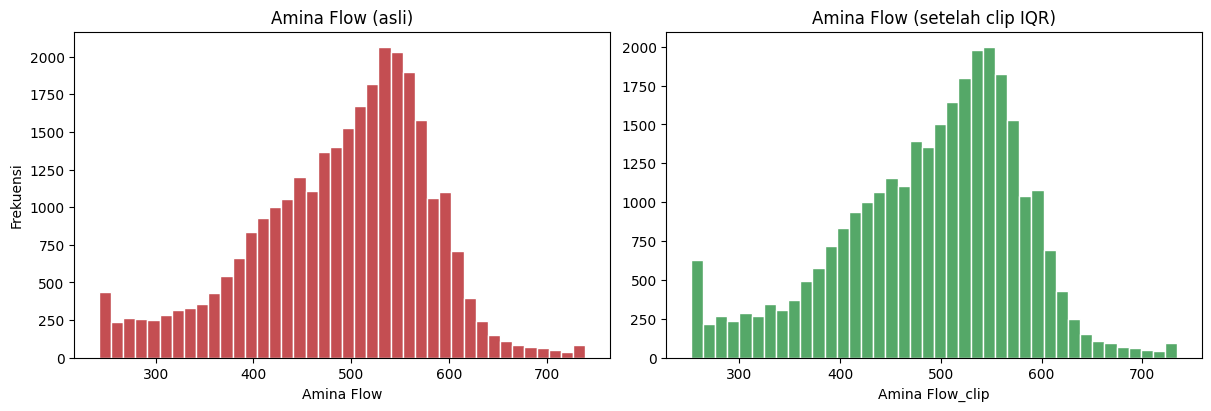

In [27]:
def clip_iqr(seri: pd.Series, k: float = 1.5) -> tuple[pd.Series, float, float]:
    """Clip nilai seri ke batas [Q1 - k*IQR, Q3 + k*IQR] dan kembalikan batasnya."""
    q1, q3 = seri.quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - k * iqr, q3 + k * iqr
    return seri.clip(lo, hi), float(lo), float(hi)


kol = "Amina Flow"
kol_clip = f"{kol}_clip"

# Memanggil fungsi clip_iqr dengan melewatkan data asli yang sudah numerik
df_sample[kol_clip], lo, hi = clip_iqr(df_sample[kol], k=1.5)

panel_plot = [
    (kol, f"{kol} (asli)", "#C44E52"),
    (kol_clip, f"{kol} (setelah clip IQR)", "#55A868"),
]

fig, axes = plt.subplots(1, 2, figsize=(12, 4), constrained_layout=True)

for ax, (nama_kol, judul, warna) in zip(axes, panel_plot):
    ax.hist(df_sample[nama_kol], bins=40, color=warna, edgecolor="white")
    ax.set_title(judul)
    ax.set_xlabel(nama_kol)

axes[0].set_ylabel("Frekuensi")
plt.show()

**Interpretation:**

Secara sederhana, **bentuk distribusinya hampir sama**, tetapi **batang paling kiri pada grafik hijau (`Amina Flow_clip`) menjadi lebih tinggi** karena nilai-nilai rendah yang keluar dari batas bawah IQR ditumpuk ke batas bawah tersebut.

### Perbedaan Utama

* **Batang paling kiri naik:** Pada grafik merah (`asli`), batang paling kiri berada di sekitar **430-an**; setelah di-*clip* (grafik hijau), batang paling kiri naik ke sekitar **620-an** karena nilai di bawah batas bawah IQR "ditahan" dan digabungkan ke batas bawah.


* **Sisi kanan & tengah tetap sama:** Bagian puncak (sekitar **530–550**) dan ekor kanan (hingga sekitar **730**) tidak berubah karena batas atas IQR tidak memotong nilai-nilai tersebut.


* **Jumlah data tetap utuh:** Tidak ada baris yang dibuang—nilai ekstrem bawah hanya dipindahkan ke batas bawahnya agar tidak terlalu menarik rata-rata ke bawah.

### c) Scatter plot with outliers marked

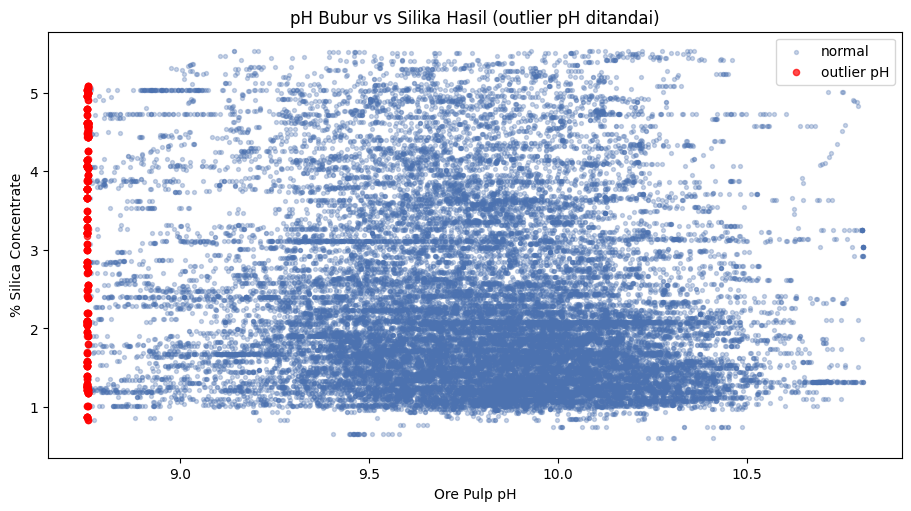

In [28]:
kol_x = "Ore Pulp pH"
kol_y = "% Silica Concentrate"
mask_ph = tandai_outlier_iqr(df_sample, kol_x)

kelompok_scatter = [
    (~mask_ph, "normal", "#4C72B0", 8, 0.3),
    (mask_ph, "outlier pH", "red", 20, 0.7),
]

fig, ax = plt.subplots(figsize=(9, 5), constrained_layout=True)

for mask_kondisi, label, warna, ukuran, alpha in kelompok_scatter:
    subset = df_sample.loc[mask_kondisi]
    ax.scatter(
        subset[kol_x],
        subset[kol_y],
        s=ukuran,
        alpha=alpha,
        color=warna,
        label=label,
    )

ax.set_title("pH Bubur vs Silika Hasil (outlier pH ditandai)")
ax.set_xlabel(kol_x)
ax.set_ylabel(kol_y)
ax.legend()
plt.show()

**Interpretation:**

Ringkasnya, grafik ini memperlihatkan bahwa **pH rendah (sekitar 8,75) tidak selalu bikin kadar silika tinggi atau rendah**:

* **Titik merah di kiri (pH ~8,75):**
  - Semua *outlier* pH berada di sisi kiri, tapi nilai `% Silica Concentrate`-nya menyebar dari sekitar **0,8 sampai 5,1**

* **Kebanyakan data (titik biru):**
  - Paling ramai berkumpul di pH sekitar **9,5–10,2** dan silika sekitar **1,2–3,5**

* **Hubungannya tidak terlihat kuat secara langsung:**
  - Saat pH rendah, kadar silika tetap bisa muncul di angka kecil maupun besar



**Intinya:** pH rendah pada data ini tidak punya pola yang pasti terhadap naik-turunnya kadar silika.

## Conclusions & Insights

Berikut adalah kesimpulan dan insight utama dari analisis data sensor flotasi yang telah kita lakukan:


### 1. Kualitas & Kelengkapan Data

* **Tidak ada *missing values* pada sampel yang diperiksa:**
  - Pada `df_sample`, seluruh kolom sensor (`Ore Pulp pH`, `Ore Pulp Density`, `Starch Flow`, `Amina Flow`, `Flotation Column 01 Air Flow`) dan target (`% Silica Concentrate`) memiliki `0` nilai kosong.
* **Perlu lanjutan verifikasi:**
  - Bebas *null* pada `df_sample` belum otomatis menjamin dataset induk (`df`) juga bebas *null*, serta belum memastikan data bebas dari anomali fisik, nilai nol yang tidak wajar, atau masalah tipe data.

### 2. Deteksi Outlier dengan IQR

* **Penyimpangan tertinggi:**
  - **Ore Pulp Density** memiliki porsi *outlier* IQR terbesar (**6,31%**, 1.892 baris) pada dataset yang diuji.
* **Penyimpangan paling rendah:**
  - **Flotation Column 01 Air Flow** (`0,00%`, 1 baris) dan **Starch Flow** (`0,13%`, 40 baris) paling jarang keluar dari rentang IQR.
* **Target & variabel proses lain:**
  - **% Silica Concentrate** memiliki **0,75%** *outlier* (226 baris), sementara **Amina Flow** (**1,43%**, 429 baris) dan **Ore Pulp pH** (**1,34%**, 402 baris) berada di kisaran penyimpangan yang relatif kecil.

### 3. Dampak Outlier Terhadap Statistik & Strategi Penanganan

* **Rata-rata vs Median pada `Amina Flow`:**
  - Nilai *median* (`504,88`) lebih tinggi daripada *rata-rata* (`489,04`), menunjukkan adanya nilai rendah yang menarik rata-rata turun. Namun, selisihnya tidak terlalu besar dan hanya bergeser menjadi `491,95` saat *outlier* IQR dikeluarkan.
* **Catatan penggunaan *clipping*:**
  - *Clipping* ke batas IQR menahan nilai ekstrem pada batas bawah/atas tanpa membuang baris data (seperti terlihat pada `Amina Flow_clip`), tetapi dampaknya pada statistik dan model tetap perlu diuji per kolom—terutama pada kolom dengan porsi *outlier* lebih besar seperti `Ore Pulp Density`—serta mempertimbangkan apakah nilai ekstrem tersebut mencerminkan kondisi proses aktual.

### 4. Insight Operasional (*Scatter Plot* pH vs Silika)

* **Pola visual penyebaran:**
  - Pada *scatter plot* `Ore Pulp pH` vs `% Silica Concentrate`, titik *outlier* pH terpusat di sisi kiri (pH `~8,75`), tetapi nilai `% Silica Concentrate` pada rentang tersebut tetap menyebar luas dari sekitar `0,8` hingga `5,1` tanpa pola garis lurus yang kuat secara visual.
* **Rekomendasi:**
  - Pengamatan pH bubur secara tunggal belum cukup untuk menjelaskan atau memprediksi kadar silika akhir; diperlukan pemeriksaan variabel proses lainnya (seperti densitas bubur dan aliran reagen) serta evaluasi multivariabel sebelum menarik kesimpulan prediktif.